# EDA conjunto — Data4Cyber (S0–S5 + S1-alt)

Análisis exploratorio sobre las ** tablas de proceso** del release, unidas en un solo
`DataFrame` con la columna `escenario`.

**Cómo se ejecuta.** La celda 0 resuelve sola la ruta de datos: monta Drive si corre en
Colab y cae a `datasets/` si corre local. No hay rutas absolutas en ninguna otra celda.
***Se utiliza hasta el escenario S5 ya que hay datos sin comprender en el escenario S6***

In [26]:
# === 0. Configuración y carga de los escenarios ===

%matplotlib inline
import os


from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)


from google.colab import drive
drive.mount("/content/gdrive/")
BASE =Path("/content/gdrive/MyDrive/TrabajoFinal/datasets/")


import pandas as pd

dfs = {
    "S0":     pd.read_csv(BASE / "datasetS0.csv"),
    "S1":     pd.read_csv(BASE / "datasetS1.csv"),
    "S1-alt": pd.read_csv(BASE / "datasetS1alt.csv"),
    "S2":     pd.read_csv(BASE / "datasetS2.csv"),
    "S3":     pd.read_csv(BASE / "datasetS3.csv"),
    "S4":     pd.read_csv(BASE / "datasetS4.csv"),
    "S5":     pd.read_csv(BASE / "datasetS5.csv"),
}
df = pd.concat(dfs.values(), ignore_index=True)

Drive already mounted at /content/gdrive/; to attempt to forcibly remount, call drive.mount("/content/gdrive/", force_remount=True).


In [27]:
from IPython.display import display
def mostrar_dfs(dfs,n):
    for k, df in dfs.items():
        print(f"=== {k} ===")
        display(df.head(n))

mostrar_dfs(dfs,5)

=== S0 ===


,timestamp,attack_active,attack_phase,attack_phase_all,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.phase_seq,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.realtime,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,...,Profile.timestamp,Profile.total_irradiance,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.phase_seq,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.realtime,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,2026-03-05 13:19:02.660000+00:00,False,normal,normal,-0.310502,-0.703539,-0.989501,50.008049,0.101279,0.39492,0.377298,0.421309,-53.832207,1,-18.320284,-16.559868,-18.952057,28.835691,-2.792666,-9.061968,3.146089,17.180131,281.451599,93.153397,88.853355,99.444839,407.938171,408.500793,408.841309,235.879349,...,NaN,NaN,-0.965705,-0.966816,-0.962146,50.005825,1.437780,9.847172,9.582252,9.602752,-5902.140137,1,-1999.145142,-1944.466309,-1958.528809,1616.824585,541.077271,517.283081,558.464233,8.863584e+08,6802.083984,2306.897217,2242.235840,2252.951416,405.437134,405.948944,406.069855,234.270035,233.998840,234.615189
1,2026-03-05 13:19:03.660000+00:00,False,normal,normal,-0.310502,-0.703539,-0.989501,50.008049,0.101279,0.39492,0.377298,0.421309,-53.832207,1,-18.320284,-16.559868,-18.952057,28.835691,-2.792666,-9.061968,3.146089,17.180131,281.451599,93.153397,88.853355,99.444839,407.938171,408.500793,408.841309,235.879349,...,NaN,NaN,-0.965705,-0.966816,-0.962146,50.005825,1.437780,9.847172,9.582252,9.602752,-5902.140137,1,-1999.145142,-1944.466309,-1958.528809,1616.824585,541.077271,517.283081,558.464233,8.863584e+08,6802.083984,2306.897217,2242.235840,2252.951416,405.437134,405.948944,406.069855,234.270035,233.998840,234.615189
2,2026-03-05 13:19:04.660000+00:00,False,normal,normal,-0.310502,-0.703539,-0.989501,50.008049,0.101279,0.39492,0.377298,0.421309,-53.832207,1,-18.320284,-16.559868,-18.952057,28.835691,-2.792666,-9.061968,3.146089,17.180131,281.451599,93.153397,88.853355,99.444839,407.938171,408.500793,408.841309,235.879349,...,NaN,NaN,-0.965705,-0.966816,-0.962146,50.005825,1.437780,9.847172,9.582252,9.602752,-5902.140137,1,-1999.145142,-1944.466309,-1958.528809,1616.824585,541.077271,517.283081,558.464233,8.863584e+08,6802.083984,2306.897217,2242.235840,2252.951416,405.437134,405.948944,406.069855,234.270035,233.998840,234.615189
3,2026-03-05 13:19:05.660000+00:00,False,normal,normal,-0.310502,-0.703539,-0.989501,50.008049,0.101279,0.39492,0.377298,0.421309,-53.832207,1,-18.320284,-16.559868,-18.952057,28.835691,-2.792666,-9.061968,3.146089,17.180131,281.451599,93.153397,88.853355,99.444839,407.938171,408.500793,408.841309,235.879349,...,NaN,NaN,-0.965705,-0.966816,-0.962146,50.005825,1.437780,9.847172,9.582252,9.602752,-5902.140137,1,-1999.145142,-1944.466309,-1958.528809,1616.824585,541.077271,517.283081,558.464233,8.863584e+08,6802.083984,2306.897217,2242.235840,2252.951416,40

=== S1 ===


,timestamp,attack_active,attack_phase,attack_phase_all,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.phase_seq,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.realtime,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,...,Profile.timestamp,Profile.total_irradiance,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.phase_seq,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.realtime,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,2026-03-06 10:49:02.510000+00:00,False,normal,normal,-0.332881,-0.257555,-0.474255,49.988049,0.100314,0.411068,0.399771,0.434722,-32.414612,1,-10.411898,-10.773335,-14.131719,90.469299,28.345638,34.930420,27.193245,17.180131,308.068573,101.483826,100.216370,106.368370,408.700775,408.817810,409.224976,236.300827,...,NaN,NaN,-0.813703,-0.813148,-0.815648,49.987865,1.023536,18.600697,18.543030,18.550619,-10367.216797,1,-3456.977783,-3443.686768,-3466.552734,7428.269531,2481.447266,2476.677002,2470.145752,8.863971e+08,12987.281250,4338.543457,4320.214844,4328.522949,403.701965,403.948517,404.038788,233.246292,232.983231,233.335754
1,2026-03-06 10:49:03.510000+00:00,False,normal,normal,-0.332881,-0.257555,-0.474255,49.988049,0.100314,0.411068,0.399771,0.434722,-32.414612,1,-10.411898,-10.773335,-14.131719,90.469299,28.345638,34.930420,27.193245,17.180131,308.068573,101.483826,100.216370,106.368370,408.700775,408.817810,409.224976,236.300827,...,NaN,NaN,-0.813703,-0.813148,-0.815648,49.987865,1.023536,18.600697,18.543030,18.550619,-10367.216797,1,-3456.977783,-3443.686768,-3466.552734,7428.269531,2481.447266,2476.677002,2470.145752,8.863971e+08,12987.281250,4338.543457,4320.214844,4328.522949,403.701965,403.948517,404.038788,233.246292,232.983231,233.335754
2,2026-03-06 10:49:04.510000+00:00,False,normal,normal,-0.332881,-0.257555,-0.474255,49.988049,0.100314,0.411068,0.399771,0.434722,-32.414612,1,-10.411898,-10.773335,-14.131719,90.469299,28.345638,34.930420,27.193245,17.180131,308.068573,101.483826,100.216370,106.368370,408.700775,408.817810,409.224976,236.300827,...,NaN,NaN,-0.813703,-0.813148,-0.815648,49.987865,1.023536,18.600697,18.543030,18.550619,-10367.216797,1,-3456.977783,-3443.686768,-3466.552734,7428.269531,2481.447266,2476.677002,2470.145752,8.863971e+08,12987.281250,4338.543457,4320.214844,4328.522949,403.701965,403.948517,404.038788,233.246292,232.983231,233.335754
3,2026-03-06 10:49:05.510000+00:00,False,normal,normal,-0.332881,-0.257555,-0.474255,49.988049,0.100314,0.411068,0.399771,0.434722,-32.414612,1,-10.411898,-10.773335,-14.131719,90.469299,28.345638,34.930420,27.193245,17.180131,308.068573,101.483826,100.216370,106.368370,408.700775,408.817810,409.224976,236.300827,...,NaN,NaN,-0.813703,-0.813148,-0.815648,49.987865,1.023536,18.600697,18.543030,18.550619,-10367.216797,1,-3456.977783,-3443.686768,-3466.552734,7428.269531,2481.447266,2476.677002,2470.145752,8.863971e+08

=== S1-alt ===


,timestamp,attack_active,attack_phase,attack_phase_all,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.phase_seq,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.realtime,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,...,Profile.timestamp,Profile.total_irradiance,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.phase_seq,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.realtime,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,2026-03-05 14:22:08.330000+00:00,False,normal,normal,-0.259700,0.260008,-0.230802,50.005424,0.111993,0.391080,0.393575,0.425378,-1.924552,1,-0.549654,1.609614,-2.984512,15.337107,4.081591,-3.653193,14.908709,17.180131,283.660004,91.616562,92.138863,99.904579,405.109619,406.373840,406.551758,234.265259,...,NaN,NaN,0.011718,-0.018026,-0.008935,50.005501,0.287292,0.965963,0.955752,0.975953,-1.664583,1,2.859485,-3.165688,-1.358381,-622.042542,-205.886154,-204.597168,-211.559189,8.863603e+08,678.595215,226.057770,223.508606,229.028824,404.915222,406.064392,405.880096,234.023102,233.856308,234.672089
1,2026-03-05 14:22:09.330000+00:00,False,normal,normal,-0.259700,0.260008,-0.230802,50.005424,0.111993,0.391080,0.393575,0.425378,-1.924552,1,-0.549654,1.609614,-2.984512,15.337107,4.081591,-3.653193,14.908709,17.180131,283.660004,91.616562,92.138863,99.904579,405.109619,406.373840,406.551758,234.265259,...,NaN,NaN,0.011718,-0.018026,-0.008935,50.005501,0.287292,0.965963,0.955752,0.975953,-1.664583,1,2.859485,-3.165688,-1.358381,-622.042542,-205.886154,-204.597168,-211.559189,8.863603e+08,678.595215,226.057770,223.508606,229.028824,404.915222,406.064392,405.880096,234.023102,233.856308,234.672089
2,2026-03-05 14:22:10.330000+00:00,False,normal,normal,-0.259700,0.260008,-0.230802,50.005424,0.111993,0.391080,0.393575,0.425378,-1.924552,1,-0.549654,1.609614,-2.984512,15.337107,4.081591,-3.653193,14.908709,17.180131,283.660004,91.616562,92.138863,99.904579,405.109619,406.373840,406.551758,234.265259,...,NaN,NaN,0.011718,-0.018026,-0.008935,50.005501,0.287292,0.965963,0.955752,0.975953,-1.664583,1,2.859485,-3.165688,-1.358381,-622.042542,-205.886154,-204.597168,-211.559189,8.863603e+08,678.595215,226.057770,223.508606,229.028824,404.915222,406.064392,405.880096,234.023102,233.856308,234.672089
3,2026-03-05 14:22:11.330000+00:00,False,normal,normal,-0.259700,0.260008,-0.230802,50.005424,0.111993,0.391080,0.393575,0.425378,-1.924552,1,-0.549654,1.609614,-2.984512,15.337107,4.081591,-3.653193,14.908709,17.180131,283.660004,91.616562,92.138863,99.904579,405.109619,406.373840,406.551758,234.265259,...,NaN,NaN,0.011718,-0.018026,-0.008935,50.005501,0.287292,0.965963,0.955752,0.975953,-1.664583,1,2.859485,-3.165688,-1.358381,-622.042542,-205.886154,-204.597168,-211.559189,8.863603e+08,678.595215,226.057770,223.508606,229.028824,404.915222,406.064392,405.880096,234.023102,233.856308,234.672089
4,2026-03-05 14:

... (4 outputs left out)

=== S4 ===


,timestamp,attack_active,attack_phase,attack_phase_all,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.phase_seq,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.realtime,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,...,Profile.timestamp,Profile.total_irradiance,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.phase_seq,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.realtime,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,2026-03-06 15:13:02.440000+00:00,False,normal,normal,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2025-09-20T09:48:00+00:00,176.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-03-06 15:13:03.440000+00:00,False,normal,normal,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2025-09-20T09:48:00+00:00,176.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-03-06 15:13:04.440000+00:00,False,normal,normal,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2025-09-20T09:48:00+00:00,176.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2026-03-06 15:13:05.440000+00:00,False,normal,normal,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2025-09-20T09:48:00+00:00,176.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-03-06 15:13:06.440000+00:00,False,normal,normal,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2025-09-20T09:48:00+00:00,176.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


=== S5 ===


,timestamp,attack_active,attack_phase,attack_phase_all,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.phase_seq,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.realtime,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,...,Profile.timestamp,Profile.total_irradiance,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.phase_seq,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.realtime,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,2026-03-06 15:56:00.430000+00:00,False,normal,normal,-0.153369,-0.092452,-0.474946,49.972595,0.112880,0.351595,0.337841,0.377779,-17.980625,1,-5.238884,-2.774879,-9.966863,89.530151,36.104263,34.166279,19.259613,17.180131,270.198547,90.473602,87.328629,92.396309,409.927124,410.483887,410.860321,236.959930,...,NaN,NaN,-0.869748,-0.906880,-0.906900,49.968521,1.577912,13.149112,12.390856,12.484709,-7776.449707,1,-2615.771973,-2563.477051,-2597.200684,3899.353516,1490.852295,1196.520752,1211.980469,8.864063e+08,8923.767578,3085.221191,2903.618408,2934.927490,405.878052,406.669708,406.881622,234.633423,234.335587,235.081772
1,2026-03-06 15:56:01.430000+00:00,False,normal,normal,-0.153369,-0.092452,-0.474946,49.972595,0.112880,0.351595,0.337841,0.377779,-17.980625,1,-5.238884,-2.774879,-9.966863,89.530151,36.104263,34.166279,19.259613,17.180131,270.198547,90.473602,87.328629,92.396309,409.927124,410.483887,410.860321,236.959930,...,NaN,NaN,-0.869748,-0.906880,-0.906900,49.968521,1.577912,13.149112,12.390856,12.484709,-7776.449707,1,-2615.771973,-2563.477051,-2597.200684,3899.353516,1490.852295,1196.520752,1211.980469,8.864063e+08,8923.767578,3085.221191,2903.618408,2934.927490,405.878052,406.669708,406.881622,234.633423,234.335587,235.081772
2,2026-03-06 15:56:02.430000+00:00,False,normal,normal,-0.153369,-0.092452,-0.474946,49.972595,0.112880,0.351595,0.337841,0.377779,-17.980625,1,-5.238884,-2.774879,-9.966863,89.530151,36.104263,34.166279,19.259613,17.180131,270.198547,90.473602,87.328629,92.396309,409.927124,410.483887,410.860321,236.959930,...,NaN,NaN,-0.869748,-0.906880,-0.906900,49.968521,1.577912,13.149112,12.390856,12.484709,-7776.449707,1,-2615.771973,-2563.477051,-2597.200684,3899.353516,1490.852295,1196.520752,1211.980469,8.864063e+08,8923.767578,3085.221191,2903.618408,2934.927490,405.878052,406.669708,406.881622,234.633423,234.335587,235.081772
3,2026-03-06 15:56:03.430000+00:00,False,normal,normal,-0.153369,-0.092452,-0.474946,49.972595,0.112880,0.351595,0.337841,0.377779,-17.980625,1,-5.238884,-2.774879,-9.966863,89.530151,36.104263,34.166279,19.259613,17.180131,270.198547,90.473602,87.328629,92.396309,409.927124,410.483887,410.860321,236.959930,...,NaN,NaN,-0.869748,-0.906880,-0.906900,49.968521,1.577912,13.149112,12.390856,12.484709,-7776.449707,1,-2615.771973,-2563.477051,-2597.200684,3899.353516,1490.852295,1196.520752,1211.980469,8.864063e+08,8923.767578,3085.221191,2903.6

In [28]:
# --- agrupación de columnas: dispositivo, tipo, fase ---
SIG_TIPO = {
    "uln1": "Tensión fase-neutro", "uln2": "Tensión fase-neutro", "uln3": "Tensión fase-neutro",
    "ull12": "Tensión fase-fase", "ull23": "Tensión fase-fase", "ull31": "Tensión fase-fase",
    "iln1": "Corriente de fase", "iln2": "Corriente de fase", "iln3": "Corriente de fase",
    "i_sum3": "Corriente de neutro",
    "pln1": "Potencia activa", "pln2": "Potencia activa", "pln3": "Potencia activa", "p_sum3": "Potencia activa",
    "sln1": "Potencia aparente", "sln2": "Potencia aparente", "sln3": "Potencia aparente", "s_sum3": "Potencia aparente",
    "qln1": "Potencia reactiva", "qln2": "Potencia reactiva", "qln3": "Potencia reactiva", "q_sum3": "Potencia reactiva",
    "cos_phi1": "Factor de potencia", "cos_phi2": "Factor de potencia", "cos_phi3": "Factor de potencia",
    "freq": "Frecuencia",
    "phase_seq": "Secuencia de fases",
    "realtime": "Marca de tiempo del equipo",
}
UNIDAD = {
    "Tensión fase-neutro": "V", "Tensión fase-fase": "V", "Corriente de fase": "A",
    "Corriente de neutro": "A", "Potencia activa": "W", "Potencia aparente": "VA",
    "Potencia reactiva": "var", "Factor de potencia": "—", "Frecuencia": "Hz",
    "Secuencia de fases": "—", "Marca de tiempo del equipo": "s",
    "SOC": "fracción 0-1", "Señal de precio": "EUR/kWh", "Contexto de escenario": "—",
    "Control / etiquetas": "—", "Desconocido": "?",
}
FASE = {"ull12": "L1-L2", "ull23": "L2-L3", "ull31": "L3-L1"}

def partir(c):
    if "." in c:
        dev, sig = c.split(".", 1)
    else:
        dev, sig = "(sin prefijo)", c
    return dev, sig

def tipo_de(dev, sig):
    if dev == "(sin prefijo)":
        return "Control / etiquetas"
    if dev.startswith("Battery-SOC"):
        return "SOC"
    if dev == "MQTT-Price-Signal":
        return "Señal de precio"
    if dev == "Profile":
        return "Contexto de escenario"
    return SIG_TIPO.get(sig, "Desconocido")

def fase_de(sig):
    if sig in FASE:
        return FASE[sig]
    if sig.endswith("sum3"):
        return "trifásica"
    if sig.endswith("1"):
        return "L1"
    if sig.endswith("2"):
        return "L2"
    if sig.endswith("3"):
        return "L3"
    return "—"

reg = []
for c in df.columns:
    dev, sig = partir(c)
    t = tipo_de(dev, sig)
    reg.append({"columna": c, "dispositivo": dev, "señal": sig,
                "tipo": t, "unidad": UNIDAD.get(t, "?"), "fase": fase_de(sig)})
cols = pd.DataFrame(reg)

print("columnas:", len(cols), "| dispositivos:", cols.dispositivo.nunique(), "| tipos:", cols.tipo.nunique())
print("\n--- por dispositivo ---")
por_dev = (cols.groupby("dispositivo")
           .agg(columnas=("columna", "size"), tipos=("tipo", lambda s: ", ".join(sorted(set(s)))))
           .sort_values("columnas", ascending=False))
display(por_dev)

columnas: 155 | dispositivos: 10 | tipos: 15

--- por dispositivo ---


,columnas,tipos
dispositivo,,
BSS-Inverter-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Load-B-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Substation-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Load-A-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
PV-Inverter-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Profile,8,Contexto de escenario
(sin prefijo),4,Control / etiquetas
Battery-SOC-Reported,1,SOC
Battery-SOC-Reference,1,SOC


## 2. Datos Nulos

En este release **una celda vacía no es un cero ni un `NaN` imputado: es ausencia de valor de origen**.

In [29]:
# --- vacíos por columna y por fila ---

num = df.select_dtypes(include=[np.number])
no_num = [c for c in df.columns if c not in num.columns]
miss = df.isna()

print(f"columnas numéricas: {len(num.columns)} | no numéricas: {len(no_num)}")
if no_num:
    print("no numéricas:", no_num)

print(f"celdas vacías: {int(miss.values.sum()):,} de {miss.size:,} ({miss.values.mean()*100:.2f} %)")
print(f"filas con algún vacío: {int((miss.sum(axis=1) > 0).sum()):,} de {len(miss):,}")

por_col = miss.mean().mul(100).sort_values(ascending=False)
con_vacios = por_col[por_col > 0]
print(f"ncolumnas con al menos un vacío: {len(con_vacios)} de {len(por_col)}")
print("\ntop 15 columnas más incompletas (%):")
print(con_vacios.head(15).round(2).to_string())
#print(con_vacios.index.tolist())



columnas numéricas: 150 | no numéricas: 5
no numéricas: ['timestamp', 'attack_active', 'attack_phase', 'attack_phase_all', 'Profile.timestamp']
celdas vacías: 6,512 de 1,945,870 (0.33 %)
filas con algún vacío: 641 de 12,554
ncolumnas con al menos un vacío: 151 de 155

top 15 columnas más incompletas (%):
MQTT-Price-Signal.price_eur_per_kwh    4.25
Battery-SOC-Reported.soc_value         1.44
Profile.timestamp                      1.40
Profile.pv_active_kw                   1.40
Profile.load2_kw                       1.40
Profile.load1_kw                       1.40
Profile.ambient_temperature            1.40
Profile.total_irradiance               1.40
Profile.pv_input_kw                    1.40
Profile.pv_reactive_kvar               1.40
Battery-SOC-Reference.soc_value        0.39
BSS-Inverter-AC-Meter.qln2             0.25
BSS-Inverter-AC-Meter.qln3             0.25
BSS-Inverter-AC-Meter.realtime         0.25
BSS-Inverter-AC-Meter.s_sum3           0.25


 # Eliminar columnas sin aporte
 por ahora vamos a descartar las columas que involucren marcas temporales y etapas del ataque ya que no estamos interezados en analizar estas caracteristicas.
"

In [30]:
def eliminar_columnas(df):
    df = df.drop(columns=["attack_phase", "attack_phase_all","Profile.timestamp","timestamp"])
    df = df.drop(columns=[c for c in df.columns if "realtime" in c ])
    df = df.drop(columns=[c for c in df.columns if "phase_seq" in c ])
    return df

dfs={k: eliminar_columnas(df) for k, df in dfs.items()}


# Imputacion de datos 

In [32]:
dfs2={k:df[df.columns[df.isna().any()]] for k, df in dfs.items()}
mostrar_dfs(dfs2,3)

=== S0 ===


,Battery-SOC-Reference.soc_value,Battery-SOC-Reported.soc_value,MQTT-Price-Signal.price_eur_per_kwh,Profile.ambient_temperature,Profile.load1_kw,Profile.load2_kw,Profile.pv_active_kw,Profile.pv_input_kw,Profile.pv_reactive_kvar,Profile.total_irradiance
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.199597,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.199597,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


=== S1 ===


,Battery-SOC-Reference.soc_value,Battery-SOC-Reported.soc_value,MQTT-Price-Signal.price_eur_per_kwh,Profile.ambient_temperature,Profile.load1_kw,Profile.load2_kw,Profile.pv_active_kw,Profile.pv_input_kw,Profile.pv_reactive_kvar,Profile.total_irradiance
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.186243,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.186243,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


=== S1-alt ===


,Battery-SOC-Reference.soc_value,Battery-SOC-Reported.soc_value,MQTT-Price-Signal.price_eur_per_kwh,Profile.ambient_temperature,Profile.load1_kw,Profile.load2_kw,Profile.pv_active_kw,Profile.pv_input_kw,Profile.pv_reactive_kvar,Profile.total_irradiance
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


... (4 outputs left out)

=== S4 ===


,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,BSS-Inverter-AC-Meter.uln2,BSS-Inverter-AC-Meter.uln3,Battery-SOC-Reference.soc_value,Battery-SOC-Reported.soc_value,Load-A-AC-Meter.cos_phi1,Load-A-AC-Meter.cos_phi2,...,PV-Inverter-AC-Meter.ull31,PV-Inverter-AC-Meter.uln1,PV-Inverter-AC-Meter.uln2,PV-Inverter-AC-Meter.uln3,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.038479,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.038479,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


=== S5 ===


,Battery-SOC-Reference.soc_value,Battery-SOC-Reported.soc_value,MQTT-Price-Signal.price_eur_per_kwh,Profile.ambient_temperature,Profile.load1_kw,Profile.load2_kw,Profile.pv_active_kw,Profile.pv_input_kw,Profile.pv_reactive_kvar,Profile.total_irradiance
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.199941,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.199941,NaN,0.0564,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
def imputar_filas_con_nulos(df):
    columnas_con_nulos = df.columns[df.isna().any()]
    for col in columnas_con_nulos:
        df[col] = df[col].fillna(df[col].mean())
    return df

dfs={k: imputar_filas_con_nulos(df) for k, df in dfs.items()}

# Split de Datos
Debido a la naturaleza temporal e interdependiente de las variables de telemetría ciberfísica, aplicar una división aleatoria convencional (*random train-test split*) introduce el riesgo de data leakage y overfitting, ya que el modelo tiende a memorizar tendencias continuas o correlaciones contiguas dentro de un mismo episodio operacional. Para capturar la dinámica secuencial de los sensores sin contaminar el entrenamiento, los datos se estructuraron mediante rolling windows de 20 pasos temporales hacia atrás. Asimismo, la validación del modelo se diseñó bajo un esquema de Leave-One-Scenario-Out(LOSO), lo que garantiza que el conjunto de prueba contenga únicamente eventos de ataque u operación completamente inéditos, evaluando con rigor la capacidad real de generalización del sistema ante situaciones no vistas

In [36]:
def separar_variables(df):
    dfX = df.drop(["attack_active"],axis=1)
    dfY = df["attack_active"]
    return dfX, dfY


dfsX, dfsY = {}, {}
for k, df in dfs.items():
    dfsX[k], dfsY[k] = separar_variables(df)

In [37]:
def rango_movil(df, ventana=120):
    ventana_rodante = df.rolling(ventana, min_periods=1)
    maximo = ventana_rodante.max()
    minimo = ventana_rodante.min()

    return (maximo - minimo).reindex(df.index)  


dfs2={k: rango_movil(df) for k, df in dfsX.items()}
mostrar_dfs(dfs2,8)

=== S0 ===


,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,BSS-Inverter-AC-Meter.uln2,BSS-Inverter-AC-Meter.uln3,Battery-SOC-Reference.soc_value,Battery-SOC-Reported.soc_value,Load-A-AC-Meter.cos_phi1,Load-A-AC-Meter.cos_phi2,...,Profile.pv_active_kw,Profile.pv_input_kw,Profile.pv_reactive_kvar,Profile.total_irradiance,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
1,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.163638,0.000000,0.000000,0.00000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
2,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.163638,0.000000,0.000000,0.00000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
3,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.163638,0.000000,0.000000,0.00000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
4,0.689025,0.255711,0.02049,0.003685,0.041704,0.009201,0.018317,0.009123,12.460152,4.367668,5.060102,3.032377,15.8619,0.04465,15.362949,2.818767,6.959717,1.59388,3.782883,1.582947,2.444946,

=== S1 ===


,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,BSS-Inverter-AC-Meter.uln2,BSS-Inverter-AC-Meter.uln3,Battery-SOC-Reference.soc_value,Battery-SOC-Reported.soc_value,Load-A-AC-Meter.cos_phi1,Load-A-AC-Meter.cos_phi2,...,Profile.pv_active_kw,Profile.pv_input_kw,Profile.pv_reactive_kvar,Profile.total_irradiance,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000,0.0000,0.0,0.00000,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
1,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000,0.1458,0.0,0.00000,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
2,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000,0.1458,0.0,0.00000,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
3,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000,0.1458,0.0,0.00000,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
4,1.279093,0.699096,0.245318,0.00087,0.017487,0.003971,0.006475,0.01016,44.130928,18.01724,16.741507,12.27452,114.146263,30.759619,45.87742,37.509227,17.044281,3.422142,7.479004,6.143112,0.006653,0.111694,0.102966,0.0298,0.003571,0.094391,0.1458,0.0,0.01734,0.000201,...,0.0,0.0,0.0,0.0,0.001998,0.002222,0.001415,0.000546,0.043422,0.067019,0.109289,0.10182,28.4824

=== S1-alt ===


,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,BSS-Inverter-AC-Meter.uln2,BSS-Inverter-AC-Meter.uln3,Battery-SOC-Reference.soc_value,Battery-SOC-Reported.soc_value,Load-A-AC-Meter.cos_phi1,Load-A-AC-Meter.cos_phi2,...,Profile.pv_active_kw,Profile.pv_input_kw,Profile.pv_reactive_kvar,Profile.total_irradiance,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.00000,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.00000,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
2,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.00000,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.00000,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.207608,0.517314,0.13445,0.002377,0.004369,0.006325,0.02539,0.007019,24.670556,6.934627,10.072766,7.663163,93.655321,19.329231,30.669046,43.657043,9.072784,1.501465,5.92131,1.650017,0.028503,0.042816,0.093384,0.054871,0.027786,0.018463,0.000000,0.0,0.042301,0.00348,...,0.0,0.0,0.0,0.0,0.012365,0.024716,0.006804,0.001163,0.010926,0.08131

... (4 outputs left out)

=== S4 ===


,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,BSS-Inverter-AC-Meter.uln2,BSS-Inverter-AC-Meter.uln3,Battery-SOC-Reference.soc_value,Battery-SOC-Reported.soc_value,Load-A-AC-Meter.cos_phi1,Load-A-AC-Meter.cos_phi2,...,Profile.pv_active_kw,Profile.pv_input_kw,Profile.pv_reactive_kvar,Profile.total_irradiance,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.194834,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.194834,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.194834,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.194834,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.194834,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.194834,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.194834,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


=== S5 ===


,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,BSS-Inverter-AC-Meter.uln2,BSS-Inverter-AC-Meter.uln3,Battery-SOC-Reference.soc_value,Battery-SOC-Reported.soc_value,Load-A-AC-Meter.cos_phi1,Load-A-AC-Meter.cos_phi2,...,Profile.pv_active_kw,Profile.pv_input_kw,Profile.pv_reactive_kvar,Profile.total_irradiance,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.003401,0.0,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.003401,0.0,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.003401,0.0,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.039733,0.139829,0.069832,0.001072,0.035015,0.020233,0.016092,0.019053,9.638258,2.56952,4.33364,2.735099,11.026039,9.244732,9.909983,8.128668,4.096313,2.346046,3.573448,1.823189,0.133057,0.154724,0.071625,0.051636,0.088608,0.067322,0.003401,0.0,0.006855,0.016511,...,0.0,0.0,0.0,0.0,0.001886,0.00224,0.002676,0.002987,0.109909

In [44]:
def drop_primeras(df, n):
    return df.iloc[n:].reset_index(drop=True)
dfsX={k: drop_primeras(df,4) for k, df in dfsX.items()}
dfsY={k: drop_primeras(df,4) for k, df in dfsY.items()}
print(dfsX["S1"].head(5),dfsY["S1"].head(5))

   BSS-Inverter-AC-Meter.cos_phi1  BSS-Inverter-AC-Meter.cos_phi2  BSS-Inverter-AC-Meter.cos_phi3  BSS-Inverter-AC-Meter.freq  BSS-Inverter-AC-Meter.i_sum3  \
0                       -0.018978                       -0.137548                       -0.240023                   49.991474                      0.095695   
1                       -0.018978                       -0.137548                       -0.240023                   49.991474                      0.095695   
2                       -0.018978                       -0.137548                       -0.240023                   49.991474                      0.095695   
3                        0.271751                        0.429660                       -0.133367                   49.993370                      0.111991   
4                        0.271751                        0.429660                       -0.133367                   49.993370                      0.111991   

   BSS-Inverter-AC-Meter.iln1  BSS-Inverter-A

rango mediana antes del ataque: 14111.7
rango mediana durante el ataque: 3577.3


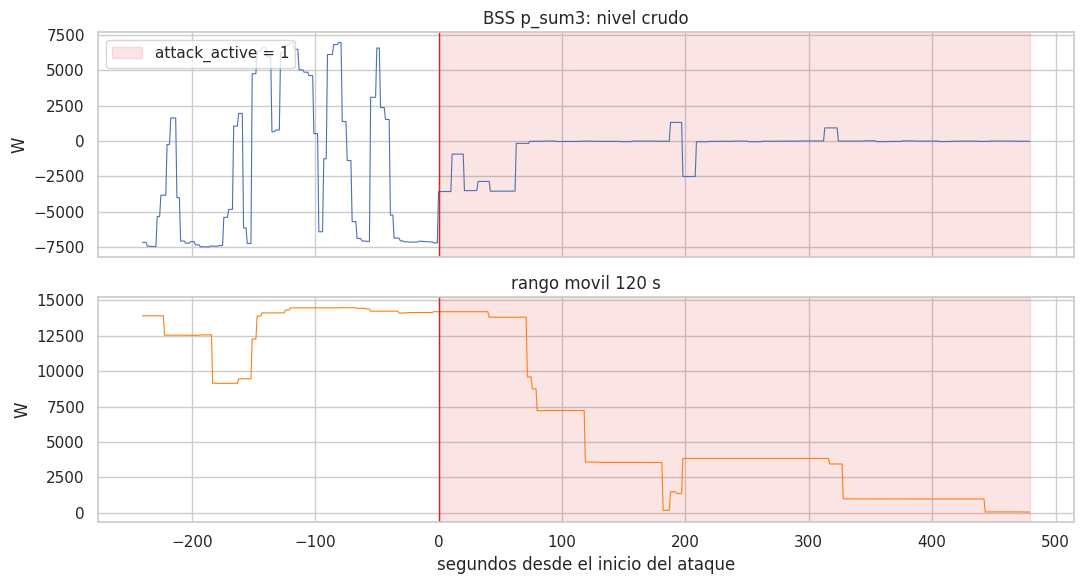

In [39]:
# --- ubica el primer ataque sostenido en S3 y compara nivel crudo contra rango movil ---

def primer_ataque_sostenido(etiquetas, minimo=60):
    """Posicion del primer ataque que dura al menos `minimo` filas seguidas."""
    racha = 0
    for i, valor in enumerate(etiquetas):
        racha = racha + 1 if valor else 0
        if racha >= minimo:
            return i - minimo + 1
    return None


senal = "BSS-Inverter-AC-Meter.p_sum3"
escenario = "S3"

# --- series del escenario elegido: etiqueta, nivel crudo y rango movil ---
y_s3 = dfsY[escenario].to_numpy()
crudo = dfsX[escenario][senal].to_numpy()
rango = dfs2[escenario][senal].to_numpy()

inicio_rel = primer_ataque_sostenido(y_s3)
if inicio_rel is None:
    raise ValueError(f"sin ataque sostenido de 60 filas en {escenario}")

# --- ventana de 240 filas antes y 480 despues, recortada a los limites del escenario ---
inicio = max(inicio_rel - 240, 0)
fin = min(inicio_rel + 480, len(y_s3))
ventana = np.arange(inicio, fin)
x = ventana - inicio_rel
ataque = y_s3[ventana] == 1

fig, ejes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ejes[0].plot(x, crudo[ventana], lw=0.8)
ejes[0].set_title("BSS p_sum3: nivel crudo")
ejes[1].plot(x, rango[ventana], lw=0.8, color="tab:orange")
ejes[1].set_title("rango movil 120 s")
ejes[1].set_xlabel("segundos desde el inicio del ataque")

# --- sombrea solo hasta la ultima fila con attack_active = 1 dentro de la ventana ---
fin_ataque = x[ataque].max() if ataque.any() else 0
for eje in ejes:
    eje.axvspan(0, fin_ataque, color="tab:red", alpha=0.12, label="attack_active = 1")
    eje.axvline(0, color="tab:red", lw=1)
    eje.set_ylabel("W")
ejes[0].legend(loc="upper left")

# --- mediana del rango antes (x < 0) y durante el ataque, en la ventana ---
antes = x < 0
print("rango mediana antes del ataque:", round(float(np.nanmedian(rango[ventana][antes])), 1))
print("rango mediana durante el ataque:", round(float(np.nanmedian(rango[ventana][ataque])), 1))

fig.tight_layout()
plt.show()


**Random Forest (RF baseline):** Se configuró formalmente con **120 árboles**, profundidad máxima de **18**, un tamaño mínimo de muestra por hoja de **2** y ponderación de clases balanceada (`class_weight='balanced'`)[1].

In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score)

PARAMS_RF = {
    "n_estimators": 120,
    "max_depth": 18,
    "min_samples_leaf": 2,
    "class_weight": "balanced",
    "random_state": 42,
    "n_jobs": -1,
}

escenarios = list(dfsX)
resultados = []
predicciones = {}

# --- un fold por escenario: entrena con los demas, predice el que queda afuera ---
for test in escenarios:
    X_train = pd.concat([dfsX[k] for k in escenarios if k != test], ignore_index=True)
    y_train = pd.concat([dfsY[k] for k in escenarios if k != test], ignore_index=True)
    X_test = dfsX[test].to_numpy()
    y_test = dfsY[test].to_numpy()

    rf = RandomForestClassifier(**PARAMS_RF).fit(X_train, y_train)
    pred = rf.predict(X_test)
    predicciones[test] = (y_test, pred)

    resultados.append({
        "escenario": test,
        "n": len(y_test),
        "positivos": int(y_test.sum()),
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
    })

tabla_rf = pd.DataFrame(resultados).set_index("escenario").round(3)
print("RF LOSO: 120 arboles, depth 18, leaf 2, class_weight=balanced")
display(tabla_rf)

# --- metricas globales sobre las predicciones out-of-fold de los 7 folds ---
y_true = np.concatenate([predicciones[k][0] for k in escenarios])
y_pred = np.concatenate([predicciones[k][1] for k in escenarios])
print("global accuracy:", round(accuracy_score(y_true, y_pred), 3))
print("global confusion matrix [[TN FP], [FN TP]]:")
print(confusion_matrix(y_true, y_pred))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local

RF LOSO: 120 arboles, depth 18, leaf 2, class_weight=balanced


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


,n,positivos,accuracy,precision,recall,f1
escenario,,,,,,
S0,1798,0,0.533,0.000,0.000,0.000
S1,1798,913,0.587,1.000,0.186,0.314
S1-alt,1792,910,0.819,0.744,0.982,0.847
S2,1768,903,0.674,0.866,0.429,0.573
S3,1800,912,0.758,0.851,0.633,0.726
S4,1798,1257,0.616,1.000,0.450,0.621
S5,1800,1341,0.597,0.936,0.493,0.646


global accuracy: 0.655
global confusion matrix [[TN FP], [FN TP]]:
[[4964 1354]
 [2981 3255]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score)

PARAMS_RF = {
    "n_estimators": 120,
    "max_depth": 18,
    "min_samples_leaf": 2,
    "class_weight": "balanced",
    "random_state": 42,
    "n_jobs": -1,
}

escenarios = list(dfsX)
resultados = []
predicciones = {}

# --- un fold por escenario: entrena con los demas, predice el que queda afuera ---
for test in escenarios:
    X_train = pd.concat([dfsX[k] for k in escenarios if k != test], ignore_index=True)
    y_train = pd.concat([dfsY[k] for k in escenarios if k != test], ignore_index=True)
    X_test = dfsX[test].to_numpy()
    y_test = dfsY[test].to_numpy()

    rf = RandomForestClassifier(**PARAMS_RF).fit(X_train, y_train)
    pred = rf.predict(X_test)
    predicciones[test] = (y_test, pred)

    resultados.append({
        "escenario": test,
        "n": len(y_test),
        "positivos": int(y_test.sum()),
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
    })

tabla_rf = pd.DataFrame(resultados).set_index("escenario").round(3)
print("RF LOSO: 120 arboles, depth 18, leaf 2, class_weight=balanced")
display(tabla_rf)

# --- metricas globales sobre las predicciones out-of-fold de los 7 folds ---
y_true = np.concatenate([predicciones[k][0] for k in escenarios])
y_pred = np.concatenate([predicciones[k][1] for k in escenarios])
print("global accuracy:", round(accuracy_score(y_true, y_pred), 3))
print("global confusion matrix [[TN FP], [FN TP]]:")
print(confusion_matrix(y_true, y_pred))